<a href="https://colab.research.google.com/github/rawanmd/segmentation_coverless_steg/blob/adaptive_window/Segmentation_Coverless_Steg_Mask_R_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from textwrap import indent
from google.colab import drive

import os
import glob
import json
import time
import math
import numpy as np

import torchvision
import torchvision.transforms.functional as F
import cv2
import matplotlib.pyplot as plt
import torch

In [2]:
INVERTED_INDEX_FILEPATH : str = "/content/drive/MyDrive/coco_dataset/inverted_index.json"

## Connect to Drive

In [3]:
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

# Dataset root
dataset_dir = "/content/drive/MyDrive/coco_dataset"
os.makedirs(dataset_dir, exist_ok=True)

# Move into dataset folder
%cd $dataset_dir

# Create desired folders
os.makedirs("annotations", exist_ok=True)
os.makedirs("train", exist_ok=True)
os.makedirs("val", exist_ok=True)

# ==========================
# 1. ANNOTATIONS
# ==========================
# !wget -c http://images.cocodataset.org/annotations/annotations_trainval2017.zip

# !unzip -q annotations_trainval2017.zip
# !rm annotations_trainval2017.zip

# # ==========================
# # 2. VALIDATION IMAGES
# # ==========================
# !wget -c http://images.cocodataset.org/zips/val2017.zip

# !unzip -q val2017.zip
# !rm val2017.zip

# # Move images into val/
# !mv val2017/* val/
# !rmdir val2017

# ==========================
# 3. TRAIN IMAGES
# ==========================
# !wget -c http://images.cocodataset.org/zips/train2017.zip

# !unzip -q train2017.zip
# !rm train2017.zip

# # Move images into train/
# !mv train2017/* train/
# !rmdir train2017

Mounted at /content/drive
/content/drive/MyDrive/coco_dataset


## Import Mask R-CNN

In [9]:
mask_rcnn_model = torchvision.models.detection.maskrcnn_resnet50_fpn(
    weights="DEFAULT"
)
mask_rcnn_model.eval()

MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(in

## Functions

In [10]:
def extract_masks(image_path):

  image = cv2.imread(image_path)
  image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  masks = mask_rcnn_model([F.to_tensor(image)])[0]

  binary_seq = ""
  pix = 0

  for i in range(masks['boxes'].shape[0]-1):
    x1, y1 = masks['boxes'][i][0].item(), masks['boxes'][i][1].item()

    x2, y2 = masks['boxes'][i+1][0].item(), masks['boxes'][i+1][1].item()

    d_squared = (x2 - x1)**2 + (y2 - y1)**2
    d = math.sqrt(d_squared)

    if(d <= 300):
      binary_seq += '0'
    else:
      binary_seq += '1'

  r, _, _ = cv2.split(image)
  pix = np.mean(r)

  return binary_seq, int(pix)



def get_image_paths(dir):
  image_paths = sorted(glob.glob(os.path.join(dir, '*.jpg')))
  print(f"Found {len(image_paths)} images.")
  return image_paths



def build_index(image_paths):
  index = {}
  image_paths = get_image_paths(image_paths)
  print(f"image_paths: {image_paths}")
  for image_path in image_paths:
    # call segmentation model
    binary_seq, pix = extract_masks(image_path)

    if binary_seq is None or binary_seq == "":
      continue

    if binary_seq not in index:
      index[binary_seq] = []

    index[binary_seq].append({"image path": image_path,
                              "pix": pix})

    with open(str(dataset_dir)+"/inverted_index.json", "w") as f:
      json.dump(index, f, indent=4)

  return index

In [11]:
def match_msg_to_images(binary_msg: str, window_size: int, prefix_maps: dict) -> (list[str], int, int):
  """
  finds the optimal window size and matches images in the inverted index with the binary representation of the message.

  Searches using an index with variable-length keys.The scan window is sized to the longest key in the index, ensuring
  that all possible key matches can be detected.

  Args:
    binary_msg (str): Binary representation of the secret message.
    window_size (int): Maximum window size available in the inverted index.
    inverted_index (dict): contains all binary_sequences extracted from the images in the dataset and the images themselves.

  Returns:
    image_paths (list[str]): list of file paths of images that matched the binary message. Returns [] if matching failed.
    window_size (int): Final window size that successfully matched the entire message. Returns -1 if matching failed.
    num_zeros (int): the number of trailing zeroes that were added to the last chunk match the window size or -1 if matching failed.
  """

  for current_window_size in range(window_size, 0, -1):
    image_paths = []
    success = True
    pix_so_far = 0

    print(f"\nTrying window size: {current_window_size}")

    for i in range(0, len(binary_msg), current_window_size):

      chunk = binary_msg[i:i + current_window_size]
      num_zeros = 0

      # add trailing zeros to last chunk
      if len(chunk) < current_window_size:
          num_zeros = current_window_size - len(chunk)
          chunk = chunk.ljust(current_window_size, '0')

      print(f"chunk: {chunk}")

      keys = prefix_maps[current_window_size].get(chunk)

      if keys == None:
        print(f"No match for {chunk}")
        success = False
        break

      valid_keys = [
        key for key in keys
        if key["pix"] > pix_so_far
      ]

      if not valid_keys:
          print(f"No valid image for {chunk} after pix {pix_so_far}")
          success = False
          break

      key = min(valid_keys, key=lambda x: x["pix"])

      image_paths.append(key['image path'])
      pix_so_far = key['pix']
      print(f"key: {key}")

    if success:
      print(f"\n\nimage paths: {image_paths}")
      print(f"Final window size: {current_window_size}")
      return image_paths, current_window_size, num_zeros

  return [], -1, -1



def build_prefix_maps(inverted_index):

  prefix_maps = {}

  for binary_seq, images in inverted_index.items():

      seq_len = len(binary_seq)

      for prefix_len in range(1, seq_len + 1):

          prefix = binary_seq[:prefix_len]

          if prefix_len not in prefix_maps:
              prefix_maps[prefix_len] = {}

          if prefix not in prefix_maps[prefix_len]:
              prefix_maps[prefix_len][prefix] = []

          prefix_maps[prefix_len][prefix].extend(images)

  return prefix_maps

In [21]:
def sort_pix(image_paths):
  res = []

  for path in image_paths:
    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    r, _, _ = cv2.split(image)

    pix = (int) (np.mean(r))

    res.append((path, pix))

  print(res)

  res.sort(key=lambda x: x[1])
  return [path for path, _ in res]



def extraxt_bin_msg(image_paths, window_size, num_zeros):
  bin_msg = ''
  image_paths = sort_pix(image_paths)

  for image_path in image_paths:
    # call segmentation model
    print("Hereeee")
    binary_seq, _ = extract_masks(image_path)

    if binary_seq is None:
      continue

    bin_msg += binary_seq[:window_size]

  if num_zeros > 0:
    num_zeros *= -1
    bin_msg[:num_zeros]

  return binary_msg

In [13]:
def string_to_binary(text: str) -> str:
    """
    Converts a string into a space-separated binary representation.
    """
    return ''.join(format(ord(char), '08b') for char in text)

def binary_to_string(binary_text: str) -> str:
    """
    Converts a space-separated binary string back into text.
    """
    return ''.join(
        chr(int(binary_text[i:i+8], 2))
        for i in range(0, len(binary_text), 8)
    )

## Embedding (Matching)

In [14]:
start = time.perf_counter()

PATH = "/content/drive/MyDrive/coco_dataset/train2017"

secret_msg = "Hello World"

binary_msg = string_to_binary(secret_msg)

# build index if not already there
# inverted_index = build_index(PATH)

# load index if it exists
with open(INVERTED_INDEX_FILEPATH, "r") as f:
  inverted_index = json.load(f)

inverted_index = build_prefix_maps(inverted_index)

In [15]:
window_size = max(inverted_index.keys())
print(f"Max window size in index: {window_size}")

images, w_size, num_zeros = match_msg_to_images(binary_msg, window_size, inverted_index)
# images, w_size, num_zeros = match_msg_to_images('1101111', 4, inverted_index)  # just an example for tracing

end = time.perf_counter()

Max window size in index: 99

Trying window size: 99
chunk: 010010000110010101101100011011000110111100100000010101110110111101110010011011000110010000000000000
No match for 010010000110010101101100011011000110111100100000010101110110111101110010011011000110010000000000000

Trying window size: 98
chunk: 01001000011001010110110001101100011011110010000001010111011011110111001001101100011001000000000000
No match for 01001000011001010110110001101100011011110010000001010111011011110111001001101100011001000000000000

Trying window size: 97
chunk: 0100100001100101011011000110110001101111001000000101011101101111011100100110110001100100000000000
No match for 0100100001100101011011000110110001101111001000000101011101101111011100100110110001100100000000000

Trying window size: 96
chunk: 010010000110010101101100011011000110111100100000010101110110111101110010011011000110010000000000
No match for 010010000110010101101100011011000110111100100000010101110110111101110010011011000110010000000000

Trying

In [16]:
print(f"Keys: {images}")
print(f"\nNumber of matches: {len(images)}")
print(f"\nWindow size: {w_size}")
print(f"\nNumber of zeroes added: {num_zeros}")

Keys: ['/content/drive/MyDrive/coco_dataset/train2017/000000023380.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000021740.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000023991.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000019151.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000023444.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000020188.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000003353.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000022529.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000019047.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000023406.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000002466.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000018885.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000013332.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000024238.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000015957.jpg', '/c

In [17]:
print(f"Time taken for embedding: {end - start:.6f} seconds")

Time taken for embedding: 0.530777 seconds


## Extraction

In [18]:
start = time.perf_counter()

extracted_bin_msg = extraxt_bin_msg(images, w_size, num_zeros)
extracted_bin_msg

[('/content/drive/MyDrive/coco_dataset/train2017/000000023380.jpg', 71), ('/content/drive/MyDrive/coco_dataset/train2017/000000021740.jpg', 76), ('/content/drive/MyDrive/coco_dataset/train2017/000000023991.jpg', 81), ('/content/drive/MyDrive/coco_dataset/train2017/000000019151.jpg', 83), ('/content/drive/MyDrive/coco_dataset/train2017/000000023444.jpg', 87), ('/content/drive/MyDrive/coco_dataset/train2017/000000020188.jpg', 91), ('/content/drive/MyDrive/coco_dataset/train2017/000000003353.jpg', 94), ('/content/drive/MyDrive/coco_dataset/train2017/000000022529.jpg', 103), ('/content/drive/MyDrive/coco_dataset/train2017/000000019047.jpg', 106), ('/content/drive/MyDrive/coco_dataset/train2017/000000023406.jpg', 107), ('/content/drive/MyDrive/coco_dataset/train2017/000000002466.jpg', 110), ('/content/drive/MyDrive/coco_dataset/train2017/000000018885.jpg', 124), ('/content/drive/MyDrive/coco_dataset/train2017/000000013332.jpg', 129), ('/content/drive/MyDrive/coco_dataset/train2017/000000024

'0100100001100101011011000110110001101111001000000101011101101111011100100110110001100100'

In [19]:
extracted_msg = binary_to_string(extracted_bin_msg)

end = time.perf_counter()

extracted_msg

'Hello World'

In [20]:
print(extracted_bin_msg == binary_msg)

print(f"Time taken for extraction: {end - start:.6f} seconds")

True
Time taken for extraction: 125.379104 seconds


## Visualization

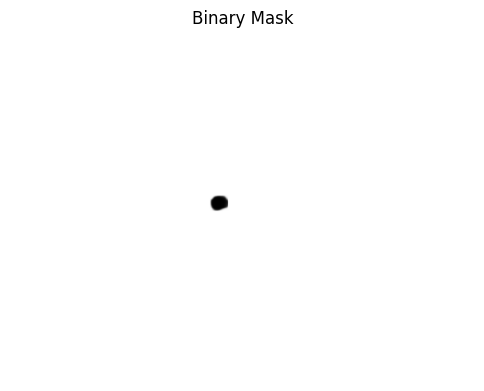

In [25]:
image = cv2.imread(images[1])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

img_tensor = F.to_tensor(image)

with torch.no_grad():
    prediction = mask_rcnn_model([img_tensor])[0]

binary_mask = prediction['masks'][0].squeeze().cpu().numpy()

plt.figure(figsize=(6, 6))
plt.imshow(binary_mask, cmap='binary')
plt.axis('off')
plt.title('Binary Mask')
plt.show()

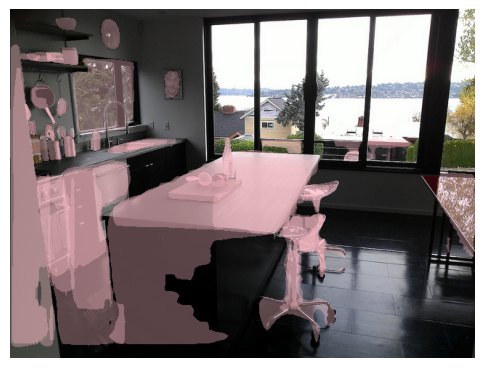

In [28]:
plt.figure(figsize=(6, 6))
plt.imshow(image)

masks = prediction["masks"]
scores = prediction["scores"]

for i in range(len(scores)):

    if scores[i] < 0:
        continue

    mask = masks[i, 0].cpu().numpy()

    binary_mask = mask > 0.5

    overlay = np.zeros(
        (binary_mask.shape[0],
          binary_mask.shape[1],
          4)
    )

    overlay[:, :, 0] = 1.0
    overlay[:, :, 1] = 0.753
    overlay[:, :, 2] = 0.796

    overlay[:, :, 3] = binary_mask * 0.35

    plt.imshow(overlay)

plt.axis("off")
plt.show()